In [3]:
from windrose import WindroseAxes
from matplotlib import pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd
import matplotlib.ticker as mtick

In [22]:
wd_data =  pd.read_csv("ORD_MDW_WS_WD_2025_2026.csv")
wd_data[["drct", "sknt"]] = wd_data[["drct", "sknt"]].apply(pd.to_numeric, errors="coerce") 

In [23]:
wd_data.head()

,station,valid,drct,sknt
0,ORD,9/1/2025 0:51,70.0,7.0
1,MDW,9/1/2025 0:53,60.0,8.0
2,ORD,9/1/2025 1:51,70.0,6.0
3,MDW,9/1/2025 1:53,50.0,6.0
4,ORD,9/1/2025 2:51,70.0,5.0


In [19]:
MDW_wd = wd_data.loc[wd_data['station']=='MDW']
ORD_wd = wd_data.loc[wd_data['station']=='ORD']
ORD_wd.head()

,station,valid,drct,sknt
0,ORD,9/1/2025 0:51,70,7
2,ORD,9/1/2025 1:51,70,6
4,ORD,9/1/2025 2:51,70,5
6,ORD,9/1/2025 3:51,50,3
8,ORD,9/1/2025 4:51,30,4


TypeError: '>' not supported between instances of 'numpy.ndarray' and 'str'

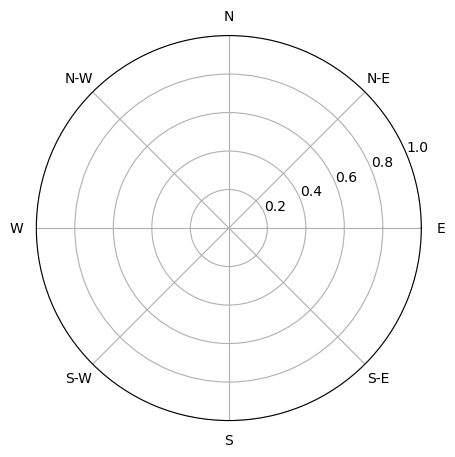

In [21]:
fig = plt.figure(figsize=(12, 5))
bins = np.arange(0, 30, 5)

ax1 = fig.add_subplot(121, projection="windrose")
ax1.bar(MDW_wd["drct"], MDW_wd["sknt"], bins=bins, normed=True, opening=0.8, edgecolor="white")
ax1.set_title("MDW")

ax2 = fig.add_subplot(122, projection="windrose")
ax2.bar(ORD_wd["drct"], ORD_wd["sknt"], bins=bins, normed=True, opening=0.8, edgecolor="white")
ax2.set_title("ORD")
ax2.set_legend(title="Wind speed (knots)", bbox_to_anchor=(1.2, 1))

rmax = max(ax1.get_ylim()[1], ax2.get_ylim()[1])
ax1.set_ylim(0, rmax)
ax2.set_ylim(0, rmax)

plt.tight_layout()
plt.show()